In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# K-Means

In [2]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# extra-code - the exact arguments of make_blobs are not important

blob_centers = np.array([[0.2,2.3],[-1.5,2.3],[-2.8,1.8],[-2.8,2.8],[-2.8,1.3]])
blob_std = np.array([0.4,0.3,0.1,0.1,0.1])
X,y = make_blobs(n_samples=2000,centers = blob_centers,cluster_std=blob_std,random_state=7)

k=5

kmeans=KMeans(n_clusters=k,n_init=10,random_state=42)
y_pred=kmeans.fit_predict(X)

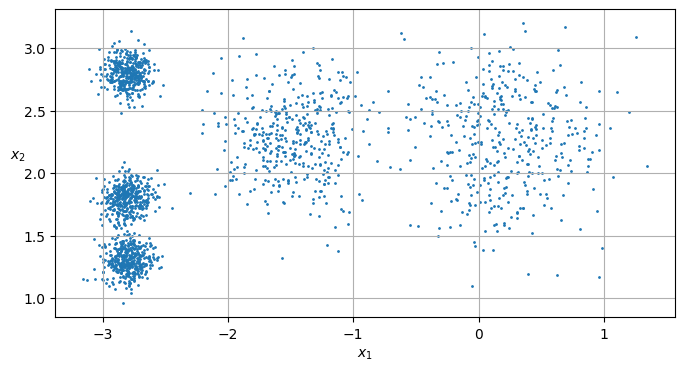

In [3]:
def plot_clusters(X,y=None):
  plt.scatter(X[:,0],X[:,1],c=y,s=1)
  plt.xlabel("$x_1$")
  plt.ylabel("$x_2$",rotation=0)

plt.figure(figsize=(8,4))
plot_clusters(X)
plt.grid()
plt.show()


In [4]:
y_pred

array([0, 0, 4, ..., 3, 1, 0], dtype=int32)

In [5]:
kmeans.labels_

array([0, 0, 4, ..., 3, 1, 0], dtype=int32)

In [6]:
y_pred is kmeans.labels_

True

In [7]:
kmeans.cluster_centers_

array([[-2.80214068,  1.55162671],
       [ 0.08703534,  2.58438091],
       [-1.46869323,  2.28214236],
       [-2.79290307,  2.79641063],
       [ 0.31332823,  1.96822352]])

In [8]:
import matplotlib.pyplot as plt

In [9]:
import numpy as np
X_new = np.array([[0,2],[3,2],[-3,3],[-3,2.5]])
kmeans.predict(X_new)

array([4, 4, 3, 3], dtype=int32)

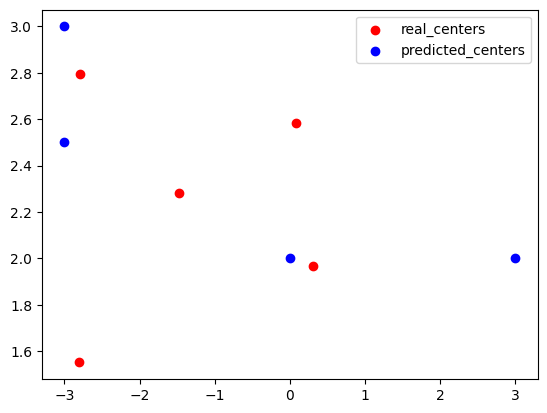

In [10]:
centers = kmeans.cluster_centers_
plt.scatter(centers[:,0],centers[:,1], c = 'red', label='real_centers')
plt.scatter(X_new[:,0],X_new[:,1],c='blue',label='predicted_centers')
plt.legend()

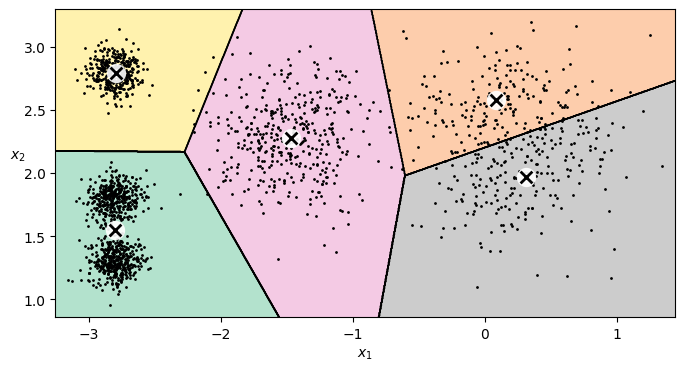

In [11]:
def plot_data(X):
   plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)


def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
   if weights is not None:
       centroids = centroids[weights > weights.max() / 10]
   plt.scatter(centroids[:, 0], centroids[:, 1],
               marker='o', s=35, linewidths=8,
               color=circle_color, zorder=10, alpha=0.9)
   plt.scatter(centroids[:, 0], centroids[:, 1],
               marker='x', s=2, linewidths=12,
               color=cross_color, zorder=11, alpha=1)


def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                            show_xlabels=True, show_ylabels=True):
   mins = X.min(axis=0) - 0.1
   maxs = X.max(axis=0) + 0.1
   xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                        np.linspace(mins[1], maxs[1], resolution))
   Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
   Z = Z.reshape(xx.shape)


   plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
               cmap="Pastel2")
   plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
               linewidths=1, colors='k')
   plot_data(X)
   if show_centroids:
       plot_centroids(clusterer.cluster_centers_)


   if show_xlabels:
       plt.xlabel("$x_1$")
   else:
       plt.tick_params(labelbottom=False)
   if show_ylabels:
       plt.ylabel("$x_2$", rotation=0)
   else:
       plt.tick_params(labelleft=False)


plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)
plt.show()

In [12]:
kmeans.transform(X_new).round(2)

array([[2.84, 0.59, 1.5 , 2.9 , 0.31],
       [5.82, 2.97, 4.48, 5.85, 2.69],
       [1.46, 3.11, 1.69, 0.29, 3.47],
       [0.97, 3.09, 1.55, 0.36, 3.36]])

In [13]:
good_init = np.array([[-3,3],[-3,2],[-3,1],[-1,2],[0,2]])
kmeans=KMeans(n_clusters=5,init=good_init,n_init=1,random_state=42)
kmeans.fit(X)

KMeans(init=array([[-3,  3],
       [-3,  2],
       [-3,  1],
       [-1,  2],
       [ 0,  2]]),
       n_clusters=5, n_init=1, random_state=42)

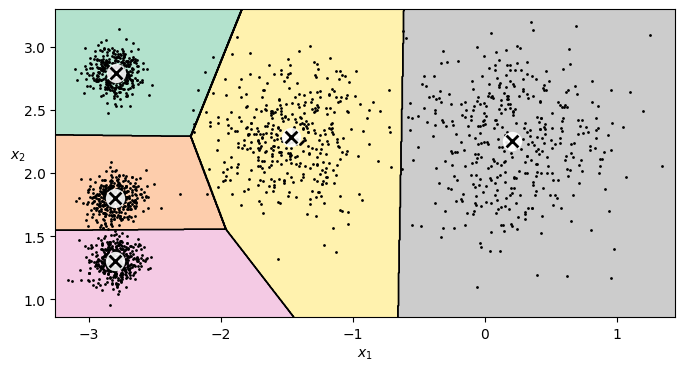

In [14]:
plt.figure(figsize=(8,4))
plot_decision_boundaries(kmeans,X)


In [15]:
kmeans.inertia_

211.59853725816828

In [16]:
kmeans.score(X)

-211.59853725816828

In [17]:
kmeans_rnd_10_inits=KMeans(n_clusters=5,init='random',n_init=10,random_state=2)
kmeans_rnd_10_inits.fit(X)

KMeans(init='random', n_clusters=5, n_init=10, random_state=2)

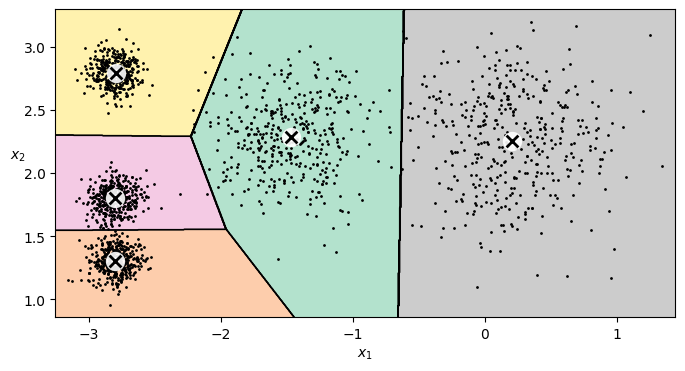

In [18]:
plt.figure(figsize=(8,4))
plot_decision_boundaries(kmeans_rnd_10_inits,X)
plt.show()

# Mini-Batch K-Means

In [19]:
from sklearn.cluster import MiniBatchKMeans

minibatch_kmeans=MiniBatchKMeans(n_clusters=5,n_init=3,random_state=42)
minibatch_kmeans.fit(X)

MiniBatchKMeans(n_clusters=5, n_init=3, random_state=42)

In [20]:
minibatch_kmeans.inertia_


211.65899374574317

In [21]:
kmeans_k3=KMeans(n_clusters=3,n_init=10,random_state=42)
kmeans_k8 = KMeans(n_clusters=8,n_init=10,random_state=42)

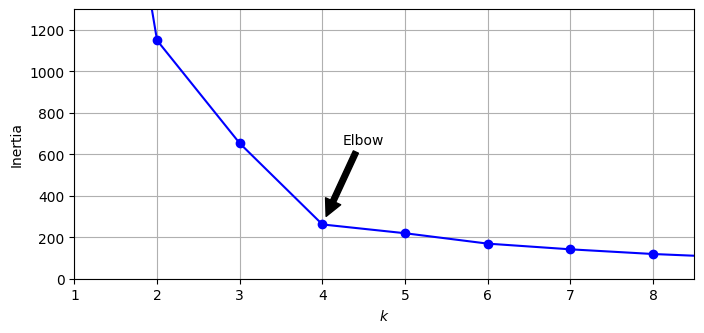

In [22]:
kmeans_per_k=[KMeans(n_clusters=k,n_init=10,random_state=42).fit(X) for k in range(1,10)]
inertias=[model.inertia_ for model in kmeans_per_k]

plt.figure(figsize=(8,3.5))
plt.plot(range(1,10),inertias,'bo-')
plt.xlabel('$k$')
plt.ylabel('Inertia')
plt.annotate("", xy=(4,inertias[3]),xytext=(4.45,650),arrowprops=dict(facecolor='black',shrink=0.1))
plt.text(4.5,650,"Elbow",horizontalalignment='center')
plt.axis([1,8.5,0,1300])
plt.grid()
plt.show()

# Limits of K-**Means**

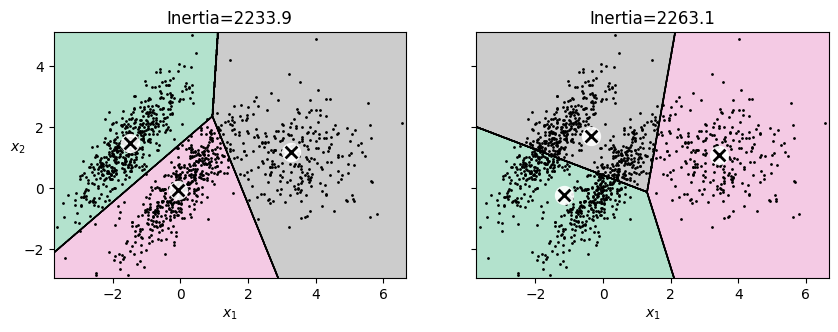

In [23]:
X1, y1 = make_blobs(n_samples=1000, centers=((4, -4), (0, 0)), random_state=42)
X1=X1.dot(np.array([[0.347,0.95],[0.732,0.598]]))
X2, y2 = make_blobs(n_samples=250, centers=1, random_state=42)
X2=X2 + [6, -8]
X=np.r_[X1,X2]
y=np.r_[y1,y2]

kmeans_good=KMeans(n_clusters=3,init=np.array([[-1.5,2.5],[0.5,0],[4,0]]),n_init=1,random_state=42)
kmeans_bad=KMeans(n_clusters=3,n_init=1,random_state=42)
kmeans_good.fit(X)
kmeans_bad.fit(X)

plt.figure(figsize=(10,3.2))
plt.subplot(121)
plot_decision_boundaries(kmeans_good,X)
plt.title(f"Inertia={kmeans_good.inertia_:.1f}")

plt.subplot(122)
plot_decision_boundaries(kmeans_bad,X,show_ylabels=False)
plt.title(f"Inertia={kmeans_bad.inertia_:.1f}")

plt.show()

In [24]:
import PIL

image=np.asarray(PIL.Image.open("/content/WhatsApp Image 2025-12-22 at 10.23.49.jpeg"))
image.shape

FileNotFoundError: [Errno 2] No such file or directory: '/content/WhatsApp Image 2025-12-22 at 10.23.49.jpeg'

In [ ]:
X=image.reshape(-1,3)
kmeans=KMeans(n_clusters=8,n_init=10,random_state=42).fit(X)
segmented_img=kmeans.cluster_centers_[kmeans.labels_]
segmented_img=segmented_img.reshape(image.shape).astype('uint8')

In [ ]:
X

In [ ]:
plt.imshow(segmented_img)


In [ ]:
segmented_img

In [ ]:
kmeans.cluster_centers_

In [ ]:
segmented_imgs = []

n_colors = (10, 8, 6, 4, 2)
for n_clusters in n_colors:
  kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=42).fit(X)
  segmented_img = kmeans.cluster_centers_[kmeans.labels_]
  segmented_imgs.append(segmented_img.reshape(image.shape))

plt.figure(figsize=(20, 10))
plt.subplots_adjust(wspace = 0.05, hspace=0.1)



plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title('Original image')
plt.axis('off')

for idx, n_clusters in enumerate(n_colors):
  plt.subplot(2, 3, 2 + idx)
  plt.imshow(segmented_imgs[idx] / 255)
  plt.title(f"{n_clusters} colors")
  plt.axis('off')

plt.show()

# Using Clustering for Semi-Supervised Learning

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np


In [ ]:
from sklearn.datasets import load_digits
X_digits,y_digits=load_digits(return_X_y=True)
X_train,y_train=X_digits[:1400],y_digits[:1400]
X_test,y_test=X_digits[1400:],y_digits[1400:]

In [ ]:
from sklearn.linear_model import LogisticRegression
n_labeled=50
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_train[:n_labeled],y_train[:n_labeled])


In [ ]:
log_reg.score(X_test,y_test)

In [ ]:
log_reg_full=LogisticRegression(max_iter=10_000)
log_reg_full.fit(X_train,y_train)
log_reg_full.score(X_test,y_test)

In [ ]:
k=50
kmeans= KMeans(n_clusters=k,n_init=10,random_state=42)
X_digits_dist=kmeans.fit_transform(X_train)
representative_digit_idx=X_digits_dist.argmin(axis=0)
X_representative_digits=X_train[representative_digit_idx]

In [ ]:
plt.figure(figsize=(8,2))
for index, X_representative_digit in enumerate(X_representative_digits):
  plt.subplot(k//10,10,index+1)
  plt.imshow(X_representative_digit.reshape(8,8),cmap='binary',interpolation='bilinear')
  plt.axis('off')

plt.show()

In [ ]:
X_representative_digit.reshape(8, 8).shape

In [ ]:
y_representative_digits = np.array([
    8,4,9,6,7,5,3,0,1,2,
    3,3,4,7,2,1,5,1,6,4,
    5,6,5,7,3,1,0,8,4,7,
    1,1,8,2,9,9,5,9,7,4,
    4,9,7,8,2,6,6,3,2,8
])

In [ ]:
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_representative_digits, y_representative_digits)
log_reg.score(X_test, y_test)

In [ ]:
log_reg.score(X_train, y_train)

In [ ]:
y_train_propagated = np.empty(len(X_train),dtype=np.int64)
for i in range(k):
  y_train_propagated[kmeans.labels_==i]=y_representative_digits[i]

In [ ]:
y_representative_digits

In [ ]:
y_train_propagated

In [ ]:
kmeans.labels_

In [ ]:
log_reg=LogisticRegression(max_iter=10_000)
log_reg.fit(X_train,y_train_propagated)

In [ ]:
log_reg.score(X_test, y_test)

In [ ]:
X_digits_dist

In [ ]:
percentile_closest = 99

X_cluster_dist = X_digits_dist[np.arange(len(X_train)),kmeans.labels_]
for i in range(k):
  in_cluster=(kmeans.labels_==i)
  cluster_dist=X_cluster_dist[in_cluster]
  cutoff_distance=np.percentile(cluster_dist,percentile_closest)
  above_cutoff=(X_cluster_dist>cutoff_distance)
  X_cluster_dist[in_cluster&above_cutoff]=-1

partially_propagated=(X_cluster_dist!=-1)
X_train_partially_propagated=X_train[partially_propagated]
y_train_partially_propagated=y_train_propagated[partially_propagated]

In [ ]:
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_train_partially_propagated,y_train_partially_propagated)
log_reg.score(X_test,y_test)

In [ ]:
(y_train_partially_propagated==y_train[partially_propagated]).mean()

# DBSCAN

In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

In [ ]:
X, y = make_moons(n_samples=1000, noise=0.05, random_state=42)
dbscan = DBSCAN(eps=0.05, min_samples=5)
dbscan.fit(X)

In [ ]:
dbscan.labels_[:10]

In [ ]:
dbscan.core_sample_indices_[:10]

In [ ]:
dbscan.components_